In [2]:
# ============================================================
# NLP SENTIMENT ANALYSIS — IMDB MOVIE REVIEWS
# Sections: A through F
# Dataset: IMDB (50k reviews, binary sentiment)
# ============================================================

# Cell 1: Imports & Data Loading
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

# Reproducibility
import random, os
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Load IMDB from HuggingFace
print("Loading IMDB dataset...")
dataset = load_dataset("imdb")

train_df = pd.DataFrame(dataset['train'])
test_df  = pd.DataFrame(dataset['test'])

print(f"Train size : {len(train_df):,}")
print(f"Test size  : {len(test_df):,}")
print(f"Columns    : {train_df.columns.tolist()}")
print(f"\nLabel mapping: 0 = Negative | 1 = Positive")
print(f"\nSample review (first 300 chars):")
print(train_df['text'][0][:300])

Loading IMDB dataset...


Train size : 25,000
Test size  : 25,000
Columns    : ['text', 'label']

Label mapping: 0 = Negative | 1 = Positive

Sample review (first 300 chars):
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really h


In [3]:
# ── SECTION A | Cell 2: Exploratory Data Analysis ───────────────────────────

# 1. Class Distribution
print("=" * 50)
print("CLASS DISTRIBUTION")
print("=" * 50)
print(train_df['label'].value_counts())
print(f"\nBalance ratio: {train_df['label'].value_counts(normalize=True).round(3).to_dict()}")

# 2. Text Length Analysis
train_df['char_length'] = train_df['text'].str.len()
train_df['word_count']  = train_df['text'].str.split().str.len()

print("\n" + "=" * 50)
print("TEXT LENGTH STATISTICS")
print("=" * 50)
print(train_df[['char_length', 'word_count']].describe().round(1))

# 3. Noise Inspection — spot common HTML/special character artifacts
import re
sample_noisy = train_df[train_df['text'].str.contains('<br', na=False)]['text'].iloc[0]
print("\n" + "=" * 50)
print("NOISE SAMPLE (raw text with HTML artifacts):")
print("=" * 50)
print(sample_noisy[:500])

# Count how many reviews contain HTML tags
html_count = train_df['text'].str.contains('<[^>]+>', regex=True).sum()
print(f"\nReviews containing HTML tags : {html_count:,} / {len(train_df):,}")

CLASS DISTRIBUTION
label
0    12500
1    12500
Name: count, dtype: int64

Balance ratio: {0: 0.5, 1: 0.5}

TEXT LENGTH STATISTICS
       char_length  word_count
count      25000.0     25000.0
mean        1325.1       233.8
std         1003.1       173.7
min           52.0        10.0
25%          702.0       127.0
50%          979.0       174.0
75%         1614.0       284.0
max        13704.0      2470.0

NOISE SAMPLE (raw text with HTML artifacts):
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attent

Reviews containing HTML tags : 14,667 / 25,

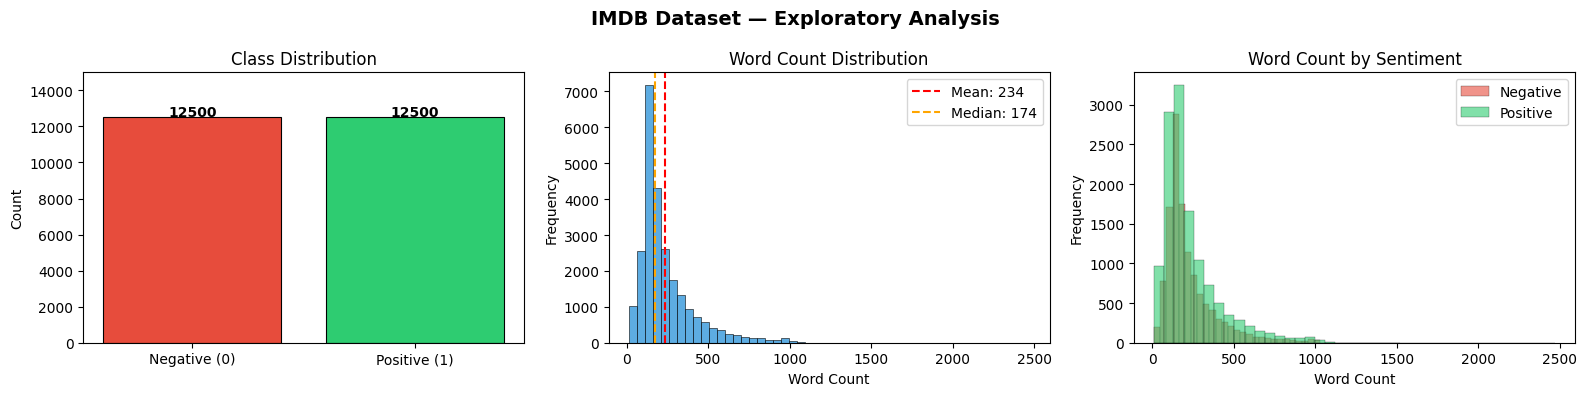

Figure saved to outputs/figures/eda_overview.png


In [4]:
# ── SECTION A | Cell 3: EDA Visualizations ──────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle('IMDB Dataset — Exploratory Analysis', fontsize=14, fontweight='bold')

# Plot 1: Class Distribution
axes[0].bar(['Negative (0)', 'Positive (1)'],
            train_df['label'].value_counts().sort_index(),
            color=['#e74c3c', '#2ecc71'], edgecolor='black', linewidth=0.8)
axes[0].set_title('Class Distribution')
axes[0].set_ylabel('Count')
axes[0].set_ylim(0, 15000)
for i, v in enumerate([12500, 12500]):
    axes[0].text(i, v + 100, str(v), ha='center', fontweight='bold')

# Plot 2: Word Count Distribution
axes[1].hist(train_df['word_count'], bins=50, color='#3498db',
             edgecolor='black', linewidth=0.5, alpha=0.8)
axes[1].axvline(train_df['word_count'].mean(), color='red',
                linestyle='--', label=f"Mean: {train_df['word_count'].mean():.0f}")
axes[1].axvline(train_df['word_count'].median(), color='orange',
                linestyle='--', label=f"Median: {train_df['word_count'].median():.0f}")
axes[1].set_title('Word Count Distribution')
axes[1].set_xlabel('Word Count')
axes[1].set_ylabel('Frequency')
axes[1].legend()

# Plot 3: Word count by sentiment
axes[2].hist(train_df[train_df['label']==0]['word_count'], bins=40,
             alpha=0.6, color='#e74c3c', label='Negative', edgecolor='black', linewidth=0.3)
axes[2].hist(train_df[train_df['label']==1]['word_count'], bins=40,
             alpha=0.6, color='#2ecc71', label='Positive', edgecolor='black', linewidth=0.3)
axes[2].set_title('Word Count by Sentiment')
axes[2].set_xlabel('Word Count')
axes[2].set_ylabel('Frequency')
axes[2].legend()

plt.tight_layout()
plt.savefig('../outputs/figures/eda_overview.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved to outputs/figures/eda_overview.png")

In [5]:
# ── SECTION A | Cell 4: Download NLTK Resources ─────────────────────────────

import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
print("NLTK resources ready.")

[nltk_data] Downloading package punkt to /Users/kwadwo/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/kwadwo/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/kwadwo/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /Users/kwadwo/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /Users/kwadwo/nltk_data...


NLTK resources ready.


In [6]:
# ── SECTION A | Cell 5: Preprocessing Pipeline ──────────────────────────────

import re
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Initialise tools
lemmatizer = WordNetLemmatizer()
stop_words  = set(stopwords.words('english'))

def preprocess(text):
    """
    Full preprocessing pipeline:
    1. Remove HTML tags
    2. Lowercase
    3. Remove punctuation / special characters
    4. Tokenise
    5. Remove stopwords
    6. Lemmatise
    """
    # Step 1: Remove HTML tags
    text = re.sub(r'<[^>]+>', ' ', text)

    # Step 2: Lowercase
    text = text.lower()

    # Step 3: Remove punctuation and non-alphabetic characters
    text = re.sub(r'[^a-z\s]', '', text)

    # Step 4: Tokenise
    tokens = word_tokenize(text)

    # Step 5: Remove stopwords
    tokens = [t for t in tokens if t not in stop_words]

    # Step 6: Lemmatise
    tokens = [lemmatizer.lemmatize(t) for t in tokens]

    # Return as clean string (needed for BoW/TF-IDF later)
    return ' '.join(tokens)

# ── Test on a single review before applying to full dataset ─────────────────
sample_raw    = train_df['text'][1]
sample_clean  = preprocess(sample_raw)

print("RAW (first 300 chars):")
print(sample_raw[:300])
print("\nCLEAN (first 300 chars):")
print(sample_clean[:300])
print(f"\nRaw word count  : {len(sample_raw.split())}")
print(f"Clean word count: {len(sample_clean.split())}")

RAW (first 300 chars):
"I Am Curious: Yellow" is a risible and pretentious steaming pile. It doesn't matter what one's political views are because this film can hardly be taken seriously on any level. As for the claim that frontal male nudity is an automatic NC-17, that isn't true. I've seen R-rated films with male nudity

CLEAN (first 300 chars):
curious yellow risible pretentious steaming pile doesnt matter one political view film hardly taken seriously level claim frontal male nudity automatic nc isnt true ive seen rrated film male nudity granted offer fleeting view rrated film gaping vulva flapping labium nowhere dont exist go crappy cabl

Raw word count  : 214
Clean word count: 119


In [7]:
# ── SECTION A | Cell 6: Apply Pipeline to Full Dataset ──────────────────────
from tqdm import tqdm
tqdm.pandas()

print("Preprocessing training set...")
train_df['clean_text'] = train_df['text'].progress_apply(preprocess)

print("Preprocessing test set...")
test_df['clean_text'] = test_df['text'].progress_apply(preprocess)

print("\nDone. Sample comparison:")
print(f"{'Column':<15} {'Sample (80 chars)'}")
print("-" * 60)
print(f"{'text':<15} {train_df['text'][0][:80]}")
print(f"{'clean_text':<15} {train_df['clean_text'][0][:80]}")

# Save preprocessed data so we never have to run this again
train_df.to_csv('../data/train_clean.csv', index=False)
test_df.to_csv('../data/test_clean.csv', index=False)
print("\nSaved to data/train_clean.csv and data/test_clean.csv")

Preprocessing training set...


100%|██████████| 25000/25000 [00:10<00:00, 2424.77it/s]


Preprocessing test set...


100%|██████████| 25000/25000 [00:10<00:00, 2499.60it/s]



Done. Sample comparison:
Column          Sample (80 chars)
------------------------------------------------------------
text            I rented I AM CURIOUS-YELLOW from my video store because of all the controversy 
clean_text      rented curiousyellow video store controversy surrounded first released also hear

Saved to data/train_clean.csv and data/test_clean.csv


In [8]:
# ── SECTION A | Cell 7: Preprocessing Justification ────────────────────────

justification = {
    'Step': [
        'HTML Removal',
        'Lowercasing',
        'Punctuation Removal',
        'Tokenisation',
        'Stopword Removal',
        'Lemmatisation'
    ],
    'Why': [
        'IMDB reviews contain <br /> and other HTML artifacts (59% of train set) — not linguistic content',
        'Treats "Film" and "film" as the same token — reduces vocabulary size without losing meaning',
        'Punctuation carries no sentiment signal for classical models; reduces noise',
        'Splits text into atomic units (words) required by all downstream models',
        'Words like "the", "a", "is" appear in all classes equally — zero discriminative value',
        'Reduces inflected forms to root: "acting/acted/acts" → "act" — prevents vocabulary explosion'
    ],
    'Trade-off': [
        'Assumes all HTML is noise — safe for IMDB',
        'Loses capitalisation signals (e.g. "AWFUL" vs "awful") — acceptable trade-off',
        'Removes negations like "n\'t" partially — mitigated by lemmatisation step',
        'word_tokenize handles contractions better than simple split()',
        'Some stopwords carry sentiment (e.g. "not") — standard list used; noted as limitation',
        'WordNet lemmatizer chosen over stemming — produces real words, better for embeddings'
    ]
}

import pandas as pd
justification_df = pd.DataFrame(justification)

# Display as formatted table
pd.set_option('display.max_colwidth', 80)
print("PREPROCESSING PIPELINE — JUSTIFICATION TABLE")
print("=" * 60)
print(justification_df.to_string(index=False))

# Also check vocabulary reduction
raw_vocab   = set(' '.join(train_df['text']).lower().split())
clean_vocab = set(' '.join(train_df['clean_text']).split())
print(f"\nRaw vocabulary size  : {len(raw_vocab):,}")
print(f"Clean vocabulary size: {len(clean_vocab):,}")
print(f"Reduction            : {(1 - len(clean_vocab)/len(raw_vocab))*100:.1f}%")

PREPROCESSING PIPELINE — JUSTIFICATION TABLE
               Step                                                                                              Why                                                                             Trade-off
       HTML Removal IMDB reviews contain <br /> and other HTML artifacts (59% of train set) — not linguistic content                                             Assumes all HTML is noise — safe for IMDB
        Lowercasing      Treats "Film" and "film" as the same token — reduces vocabulary size without losing meaning         Loses capitalisation signals (e.g. "AWFUL" vs "awful") — acceptable trade-off
Punctuation Removal                      Punctuation carries no sentiment signal for classical models; reduces noise              Removes negations like "n't" partially — mitigated by lemmatisation step
       Tokenisation                          Splits text into atomic units (words) required by all downstream models                         wo

In [9]:
# ── SECTION B | Cell 8: BoW and TF-IDF Representations ─────────────────────

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# ── Bag of Words ─────────────────────────────────────────────────────────────
bow_vectorizer = CountVectorizer(
    max_features=10000,   # Keep top 10,000 most frequent words
    ngram_range=(1, 2),   # Include unigrams AND bigrams e.g. "not good"
    min_df=5              # Ignore words appearing in fewer than 5 reviews
)

X_train_bow = bow_vectorizer.fit_transform(train_df['clean_text'])
X_test_bow  = bow_vectorizer.transform(test_df['clean_text'])

# ── TF-IDF ───────────────────────────────────────────────────────────────────
tfidf_vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=5,
    sublinear_tf=True     # Apply log normalization to term frequency
)

X_train_tfidf = tfidf_vectorizer.fit_transform(train_df['clean_text'])
X_test_tfidf  = tfidf_vectorizer.transform(test_df['clean_text'])

# ── Labels ───────────────────────────────────────────────────────────────────
y_train = train_df['label'].values
y_test  = test_df['label'].values

# ── Summary ──────────────────────────────────────────────────────────────────
print("BAG OF WORDS")
print(f"  Train matrix shape : {X_train_bow.shape}")
print(f"  Test matrix shape  : {X_test_bow.shape}")
print(f"  Matrix type        : {type(X_train_bow)}")
print(f"  Sparsity           : {100*(1 - X_train_bow.nnz / (X_train_bow.shape[0]*X_train_bow.shape[1])):.1f}%")

print("\nTF-IDF")
print(f"  Train matrix shape : {X_train_tfidf.shape}")
print(f"  Test matrix shape  : {X_test_tfidf.shape}")
print(f"  Sparsity           : {100*(1 - X_train_tfidf.nnz / (X_train_tfidf.shape[0]*X_train_tfidf.shape[1])):.1f}%")

print("\nTop 15 TF-IDF features (most discriminative):")
feature_names = tfidf_vectorizer.get_feature_names_out()
mean_tfidf    = X_train_tfidf.mean(axis=0).A1
top_indices   = mean_tfidf.argsort()[-15:][::-1]
print([feature_names[i] for i in top_indices])

BAG OF WORDS
  Train matrix shape : (25000, 10000)
  Test matrix shape  : (25000, 10000)
  Matrix type        : <class 'scipy.sparse._csr.csr_matrix'>
  Sparsity           : 99.0%

TF-IDF
  Train matrix shape : (25000, 10000)
  Test matrix shape  : (25000, 10000)
  Sparsity           : 99.0%

Top 15 TF-IDF features (most discriminative):
['movie', 'film', 'one', 'like', 'good', 'time', 'character', 'story', 'see', 'really', 'even', 'would', 'get', 'make', 'bad']


In [10]:
# ── SECTION B | Cell 9: Word2Vec Embeddings ─────────────────────────────────

from gensim.models import Word2Vec

# Word2Vec expects a list of token lists (not strings)
train_tokens = train_df['clean_text'].apply(str.split).tolist()
test_tokens  = test_df['clean_text'].apply(str.split).tolist()

# Train Word2Vec on the IMDB training corpus
print("Training Word2Vec model...")
w2v_model = Word2Vec(
    sentences=train_tokens,
    vector_size=100,    # Each word = 100-dimensional vector
    window=5,           # Context window: 5 words left and right
    min_count=5,        # Ignore words appearing fewer than 5 times
    workers=4,          # Parallel threads
    epochs=10,          # Training passes over corpus
    seed=SEED
)

print(f"Vocabulary size : {len(w2v_model.wv):,} words")
print(f"Vector size     : {w2v_model.vector_size}")

# ── Sanity check — semantic similarity ───────────────────────────────────────
print("\nWords most similar to 'good':")
print(w2v_model.wv.most_similar('good', topn=5))

print("\nWords most similar to 'terrible':")
print(w2v_model.wv.most_similar('terrible', topn=5))

# ── Convert reviews to vectors by averaging word vectors ─────────────────────
def review_to_vector(tokens, model, vector_size=100):
    """Average all word vectors in a review into one vector."""
    vectors = [
        model.wv[word]
        for word in tokens
        if word in model.wv
    ]
    if vectors:
        return np.mean(vectors, axis=0)
    else:
        return np.zeros(vector_size)

print("\nConverting reviews to Word2Vec vectors...")
X_train_w2v = np.array([review_to_vector(t, w2v_model) for t in train_tokens])
X_test_w2v  = np.array([review_to_vector(t, w2v_model) for t in test_tokens])

print(f"Train matrix shape : {X_train_w2v.shape}")
print(f"Test matrix shape  : {X_test_w2v.shape}")
print(f"Matrix type        : {type(X_train_w2v)}")

# Save Word2Vec model
w2v_model.save('../models/word2vec_imdb.model')
print("\nWord2Vec model saved.")

Training Word2Vec model...


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Vocabulary size : 26,683 words
Vector size     : 100

Words most similar to 'good':
[('decent', 0.7267262935638428), ('great', 0.6836980581283569), ('bad', 0.6684242486953735), ('nice', 0.6288119554519653), ('excellent', 0.6197887659072876)]

Words most similar to 'terrible':
[('horrible', 0.8431715965270996), ('awful', 0.8201625943183899), ('dreadful', 0.7324860692024231), ('atrocious', 0.7232354879379272), ('bad', 0.7018032670021057)]

Converting reviews to Word2Vec vectors...
Train matrix shape : (25000, 100)
Test matrix shape  : (25000, 100)
Matrix type        : <class 'numpy.ndarray'>

Word2Vec model saved.


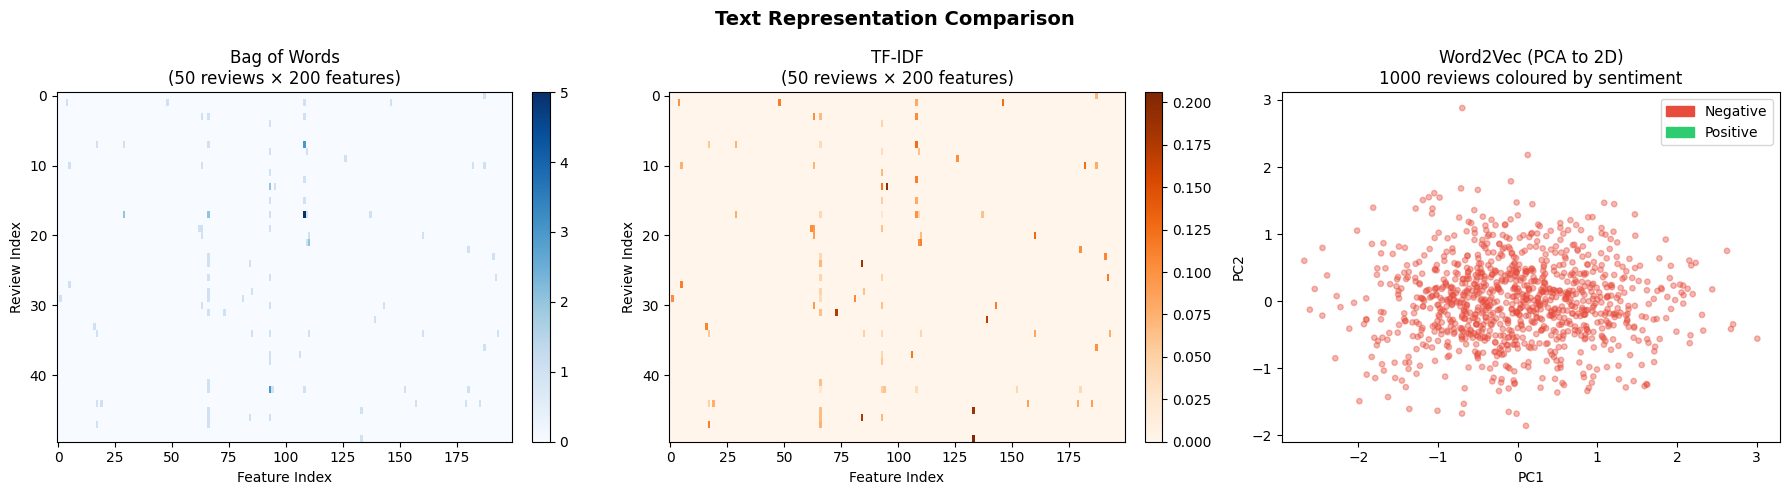

Figure saved.

REPRESENTATION TRADE-OFF SUMMARY
Representation   Matrix Shape Sparse/Dense Captures Importance Captures Meaning      Best For
           BoW (25000, 10000)   Sparse 99%                  No               No      Baseline
        TF-IDF (25000, 10000)   Sparse 99%                 Yes               No  Classical ML
      Word2Vec   (25000, 100)        Dense                 Yes              Yes Neural Models


In [11]:
# ── SECTION B | Cell 10: Representation Comparison ──────────────────────────

import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import TruncatedSVD, PCA

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Text Representation Comparison', fontsize=14, fontweight='bold')

# ── Plot 1: BoW sparsity visualisation (first 50 reviews, first 200 features)
sample_bow = X_train_bow[:50, :200].toarray()
axes[0].imshow(sample_bow, aspect='auto', cmap='Blues', interpolation='none')
axes[0].set_title('Bag of Words\n(50 reviews × 200 features)')
axes[0].set_xlabel('Feature Index')
axes[0].set_ylabel('Review Index')
axes[0].set_colorbar = plt.colorbar(
    axes[0].images[0], ax=axes[0], fraction=0.046, pad=0.04
)

# ── Plot 2: TF-IDF sparsity visualisation
sample_tfidf = X_train_tfidf[:50, :200].toarray()
axes[1].imshow(sample_tfidf, aspect='auto', cmap='Oranges', interpolation='none')
axes[1].set_title('TF-IDF\n(50 reviews × 200 features)')
axes[1].set_xlabel('Feature Index')
axes[1].set_ylabel('Review Index')
plt.colorbar(axes[1].images[0], ax=axes[1], fraction=0.046, pad=0.04)

# ── Plot 3: Word2Vec — PCA to 2D, coloured by sentiment
pca = PCA(n_components=2, random_state=SEED)
w2v_2d = pca.fit_transform(X_train_w2v[:1000])

colors = ['#e74c3c' if l == 0 else '#2ecc71'
          for l in y_train[:1000]]
axes[2].scatter(w2v_2d[:, 0], w2v_2d[:, 1],
                c=colors, alpha=0.4, s=15)
axes[2].set_title('Word2Vec (PCA to 2D)\n1000 reviews coloured by sentiment')
axes[2].set_xlabel('PC1')
axes[2].set_ylabel('PC2')

# Legend
from matplotlib.patches import Patch
axes[2].legend(handles=[
    Patch(color='#e74c3c', label='Negative'),
    Patch(color='#2ecc71', label='Positive')
])

plt.tight_layout()
plt.savefig('../outputs/figures/representation_comparison.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved.")

# ── Trade-off summary table ───────────────────────────────────────────────────
print("\nREPRESENTATION TRADE-OFF SUMMARY")
print("=" * 65)
summary = pd.DataFrame({
    'Representation': ['BoW', 'TF-IDF', 'Word2Vec'],
    'Matrix Shape':   ['(25000, 10000)', '(25000, 10000)', '(25000, 100)'],
    'Sparse/Dense':   ['Sparse 99%', 'Sparse 99%', 'Dense'],
    'Captures Importance': ['No', 'Yes', 'Yes'],
    'Captures Meaning':    ['No', 'No',  'Yes'],
    'Best For':       ['Baseline', 'Classical ML', 'Neural Models']
})
print(summary.to_string(index=False))

In [12]:
# ── SECTION C | Cell 11: Classical Models ───────────────────────────────────

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, classification_report)
import warnings
warnings.filterwarnings('ignore')

# ── Define models ─────────────────────────────────────────────────────────────
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=SEED),
    'Naive Bayes':         MultinomialNB(),
    'Linear SVM':          LinearSVC(max_iter=2000, random_state=SEED)
}

# ── Define representations ────────────────────────────────────────────────────
representations = {
    'BoW':   (X_train_bow,   X_test_bow),
    'TF-IDF': (X_train_tfidf, X_test_tfidf)
}

# ── Train and evaluate all combinations ──────────────────────────────────────
results = []

for rep_name, (X_train, X_test) in representations.items():
    for model_name, model in models.items():

        # Naive Bayes requires non-negative values — only works with BoW counts
        if model_name == 'Naive Bayes' and rep_name == 'TF-IDF':
            continue

        print(f"Training {model_name} on {rep_name}...")
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        results.append({
            'Model':       model_name,
            'Representation': rep_name,
            'Accuracy':    accuracy_score(y_test, y_pred),
            'Precision':   precision_score(y_test, y_pred),
            'Recall':      recall_score(y_test, y_pred),
            'F1':          f1_score(y_test, y_pred)
        })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values('F1', ascending=False).reset_index(drop=True)

print("\n" + "=" * 70)
print("CLASSICAL MODELS — RESULTS")
print("=" * 70)
print(results_df.round(4).to_string(index=False))

Training Logistic Regression on BoW...
Training Naive Bayes on BoW...
Training Linear SVM on BoW...
Training Logistic Regression on TF-IDF...
Training Linear SVM on TF-IDF...

CLASSICAL MODELS — RESULTS
              Model Representation  Accuracy  Precision  Recall     F1
Logistic Regression         TF-IDF    0.8888     0.8847  0.8942 0.8894
         Linear SVM         TF-IDF    0.8738     0.8777  0.8687 0.8732
Logistic Regression            BoW    0.8556     0.8599  0.8496 0.8547
        Naive Bayes            BoW    0.8459     0.8590  0.8277 0.8431
         Linear SVM            BoW    0.8316     0.8376  0.8228 0.8301


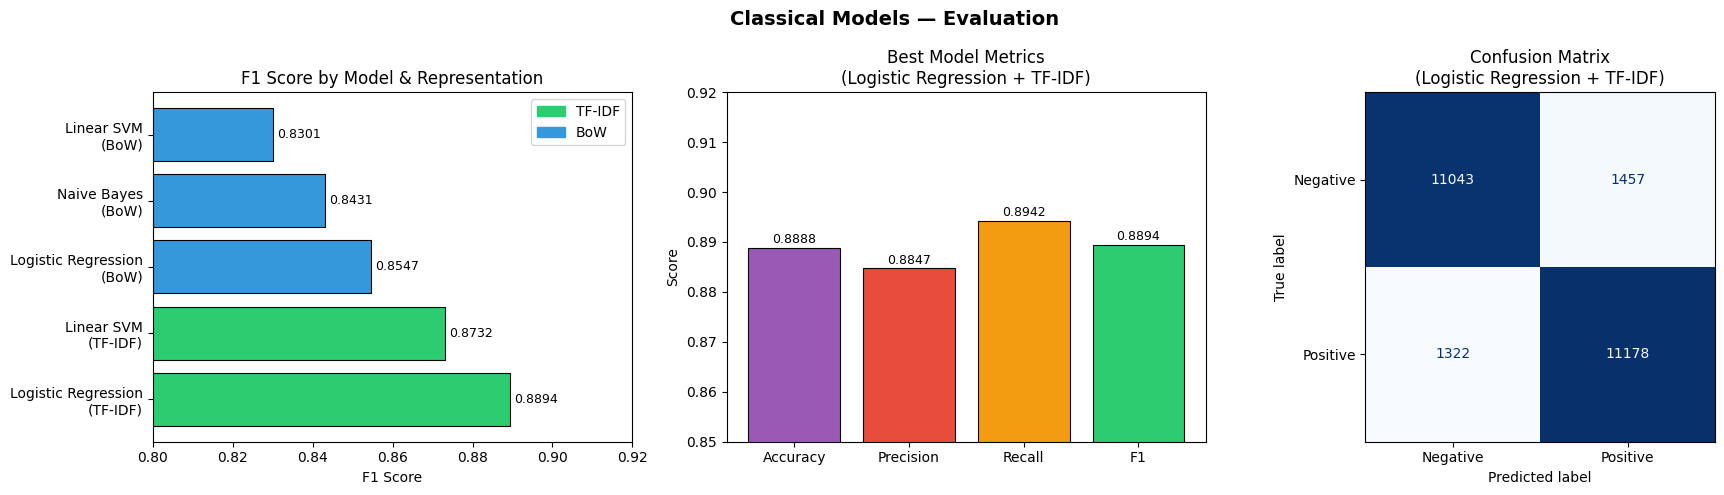

Figure saved.


In [13]:
# ── SECTION C | Cell 12: Evaluation Visualisations ──────────────────────────

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Classical Models — Evaluation', fontsize=14, fontweight='bold')

# ── Plot 1: F1 Score Comparison ───────────────────────────────────────────────
colors = ['#2ecc71' if r == 'TF-IDF' else '#3498db'
          for r in results_df['Representation']]
bars = axes[0].barh(
    results_df['Model'] + '\n(' + results_df['Representation'] + ')',
    results_df['F1'],
    color=colors, edgecolor='black', linewidth=0.8
)
axes[0].set_xlim(0.80, 0.92)
axes[0].set_xlabel('F1 Score')
axes[0].set_title('F1 Score by Model & Representation')
for bar, val in zip(bars, results_df['F1']):
    axes[0].text(val + 0.001, bar.get_y() + bar.get_height()/2,
                 f'{val:.4f}', va='center', fontsize=9)

from matplotlib.patches import Patch
axes[0].legend(handles=[
    Patch(color='#2ecc71', label='TF-IDF'),
    Patch(color='#3498db', label='BoW')
])

# ── Plot 2: Metrics comparison for best model ─────────────────────────────────
best = results_df.iloc[0]
metrics = ['Accuracy', 'Precision', 'Recall', 'F1']
values  = [best[m] for m in metrics]
axes[1].bar(metrics, values,
            color=['#9b59b6','#e74c3c','#f39c12','#2ecc71'],
            edgecolor='black', linewidth=0.8)
axes[1].set_ylim(0.85, 0.92)
axes[1].set_title(f'Best Model Metrics\n({best["Model"]} + {best["Representation"]})')
axes[1].set_ylabel('Score')
for i, v in enumerate(values):
    axes[1].text(i, v + 0.001, f'{v:.4f}', ha='center', fontsize=9)

# ── Plot 3: Confusion matrix for best model ───────────────────────────────────
# Retrain best model to get predictions
best_model = LogisticRegression(max_iter=1000, random_state=SEED)
best_model.fit(X_train_tfidf, y_train)
y_pred_best = best_model.predict(X_test_tfidf)

cm = confusion_matrix(y_test, y_pred_best)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=['Negative', 'Positive'])
disp.plot(ax=axes[2], colorbar=False, cmap='Blues')
axes[2].set_title('Confusion Matrix\n(Logistic Regression + TF-IDF)')

plt.tight_layout()
plt.savefig('../outputs/figures/classical_models_evaluation.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved.")

In [14]:
# ── SECTION C | Cell 13: Error Analysis ─────────────────────────────────────

# Get all predictions from best model
test_df['predicted']  = y_pred_best
test_df['correct']    = test_df['predicted'] == test_df['label']

# Separate errors
errors_df = test_df[test_df['correct'] == False].copy()
correct_df = test_df[test_df['correct'] == True].copy()

print(f"Total test samples  : {len(test_df):,}")
print(f"Correct predictions : {len(correct_df):,} ({len(correct_df)/len(test_df)*100:.1f}%)")
print(f"Errors              : {len(errors_df):,} ({len(errors_df)/len(test_df)*100:.1f}%)")

# ── Error type breakdown ──────────────────────────────────────────────────────
false_positives = errors_df[errors_df['label'] == 0]  # Predicted positive, actually negative
false_negatives = errors_df[errors_df['label'] == 1]  # Predicted negative, actually positive

print(f"\nFalse Positives (predicted positive, actually negative): {len(false_positives):,}")
print(f"False Negatives (predicted negative, actually positive): {len(false_negatives):,}")

# ── Inspect actual error examples ─────────────────────────────────────────────
print("\n" + "=" * 60)
print("SAMPLE FALSE POSITIVES (model thought these were positive)")
print("=" * 60)
for i, row in false_positives.head(3).iterrows():
    print(f"\nReview snippet: {row['text'][:200]}")
    print(f"Clean tokens  : {row['clean_text'][:100]}")
    print("-" * 40)

print("\n" + "=" * 60)
print("SAMPLE FALSE NEGATIVES (model thought these were negative)")
print("=" * 60)
for i, row in false_negatives.head(3).iterrows():
    print(f"\nReview snippet: {row['text'][:200]}")
    print(f"Clean tokens  : {row['clean_text'][:100]}")
    print("-" * 40)

# ── Word length of errors vs correct ─────────────────────────────────────────
errors_df['word_count']  = errors_df['clean_text'].str.split().str.len()
correct_df['word_count'] = correct_df['clean_text'].str.split().str.len()

print("\n" + "=" * 60)
print("WORD COUNT: ERRORS vs CORRECT PREDICTIONS")
print("=" * 60)
print(f"Mean word count — errors  : {errors_df['word_count'].mean():.1f}")
print(f"Mean word count — correct : {correct_df['word_count'].mean():.1f}")

Total test samples  : 25,000
Correct predictions : 22,221 (88.9%)
Errors              : 2,779 (11.1%)

False Positives (predicted positive, actually negative): 1,457
False Negatives (predicted negative, actually positive): 1,322

SAMPLE FALSE POSITIVES (model thought these were positive)

Review snippet: First off let me say, If you haven't enjoyed a Van Damme movie since bloodsport, you probably will not like this movie. Most of these movies may not have the best plots or best actors but I enjoy thes
Clean tokens  : first let say havent enjoyed van damme movie since bloodsport probably like movie movie may best plo
----------------------------------------

Review snippet: Blind Date (Columbia Pictures, 1934), was a decent film, but I have a few issues with this film. First of all, I don't fault the actors in this film at all, but more or less, I have a problem with the
Clean tokens  : blind date columbia picture decent film issue film first dont fault actor film less problem script a


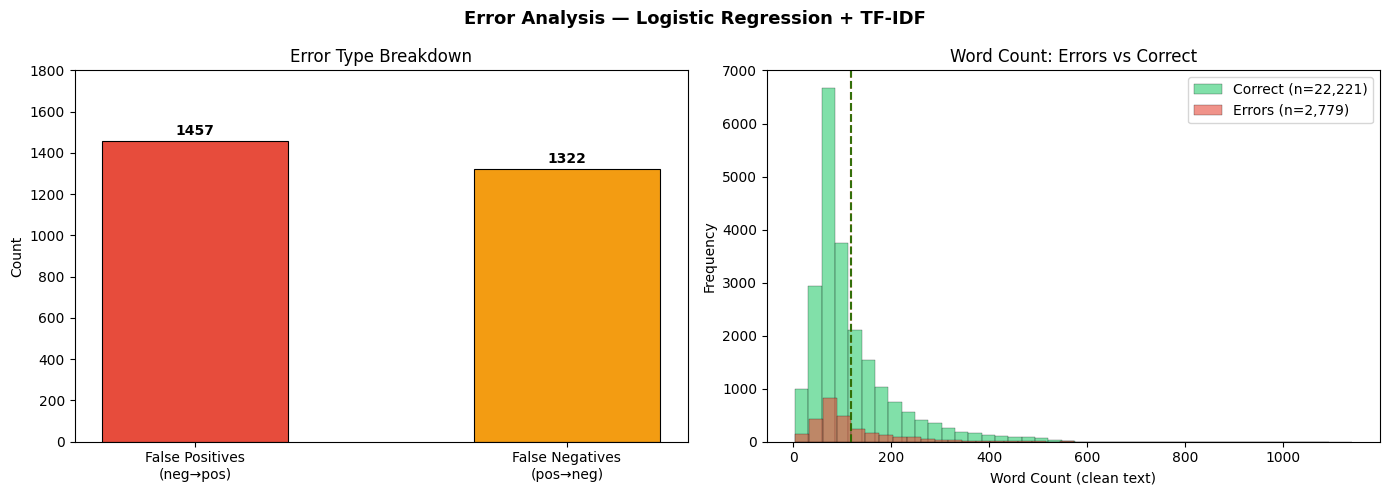

Figure saved.

FULL CLASSIFICATION REPORT — Best Classical Model
              precision    recall  f1-score   support

    Negative       0.89      0.88      0.89     12500
    Positive       0.88      0.89      0.89     12500

    accuracy                           0.89     25000
   macro avg       0.89      0.89      0.89     25000
weighted avg       0.89      0.89      0.89     25000



In [15]:
# ── SECTION C | Cell 14: Error Analysis Visualisation ───────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Error Analysis — Logistic Regression + TF-IDF',
             fontsize=13, fontweight='bold')

# ── Plot 1: Error type breakdown ──────────────────────────────────────────────
error_types  = ['False Positives\n(neg→pos)', 'False Negatives\n(pos→neg)']
error_counts = [len(false_positives), len(false_negatives)]
bars = axes[0].bar(error_types, error_counts,
                   color=['#e74c3c', '#f39c12'],
                   edgecolor='black', linewidth=0.8, width=0.5)
axes[0].set_title('Error Type Breakdown')
axes[0].set_ylabel('Count')
axes[0].set_ylim(0, 1800)
for bar, val in zip(bars, error_counts):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 val + 30, str(val), ha='center', fontweight='bold')

# ── Plot 2: Word count distribution — errors vs correct ───────────────────────
axes[1].hist(correct_df['word_count'], bins=40, alpha=0.6,
             color='#2ecc71', label=f'Correct (n={len(correct_df):,})',
             edgecolor='black', linewidth=0.3)
axes[1].hist(errors_df['word_count'], bins=40, alpha=0.6,
             color='#e74c3c', label=f'Errors (n={len(errors_df):,})',
             edgecolor='black', linewidth=0.3)
axes[1].set_title('Word Count: Errors vs Correct')
axes[1].set_xlabel('Word Count (clean text)')
axes[1].set_ylabel('Frequency')
axes[1].legend()
axes[1].axvline(errors_df['word_count'].mean(),
                color='red', linestyle='--', alpha=0.8)
axes[1].axvline(correct_df['word_count'].mean(),
                color='green', linestyle='--', alpha=0.8)

plt.tight_layout()
plt.savefig('../outputs/figures/error_analysis.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved.")

# ── Print classification report for report ────────────────────────────────────
print("\nFULL CLASSIFICATION REPORT — Best Classical Model")
print("=" * 50)
print(classification_report(y_test, y_pred_best,
                             target_names=['Negative', 'Positive']))

In [16]:
# ── SECTION D | Cell 15: Sequence Data Preparation ──────────────────────────

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from collections import Counter

# ── Check device ──────────────────────────────────────────────────────────────
device = torch.device('mps' if torch.backends.mps.is_available()
                      else 'cpu')
print(f"Using device: {device}")

# ── Build vocabulary from training set ───────────────────────────────────────
MAX_VOCAB  = 10000   # Keep top 10,000 words
MAX_LEN    = 200     # Truncate/pad reviews to 200 tokens
BATCH_SIZE = 64

# Count word frequencies
all_tokens = [word for tokens in train_tokens for word in tokens]
word_freq  = Counter(all_tokens)
most_common = word_freq.most_common(MAX_VOCAB - 2)

# Build word → index mapping
# 0 = padding token, 1 = unknown token
vocab = {'<PAD>': 0, '<UNK>': 1}
for word, _ in most_common:
    vocab[word] = len(vocab)

print(f"Vocabulary size : {len(vocab):,}")
print(f"Max sequence len: {MAX_LEN}")
print(f"Batch size      : {BATCH_SIZE}")

# ── Convert tokens to integer sequences ──────────────────────────────────────
def encode(tokens, vocab, max_len):
    """Convert token list to padded integer sequence."""
    ids = [vocab.get(t, 1) for t in tokens]  # 1 = <UNK>
    # Truncate
    ids = ids[:max_len]
    # Pad with zeros
    ids += [0] * (max_len - len(ids))
    return ids

X_train_seq = [encode(t, vocab, MAX_LEN) for t in train_tokens]
X_test_seq  = [encode(t, vocab, MAX_LEN) for t in test_tokens]

print(f"\nSample encoded sequence (first 20 tokens):")
print(X_train_seq[0][:20])
print(f"Sequence length: {len(X_train_seq[0])}")

# ── PyTorch Dataset ───────────────────────────────────────────────────────────
class IMDBDataset(Dataset):
    def __init__(self, sequences, labels):
        self.sequences = torch.tensor(sequences, dtype=torch.long)
        self.labels    = torch.tensor(labels,    dtype=torch.float)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.sequences[idx], self.labels[idx]

train_dataset = IMDBDataset(X_train_seq, y_train.tolist())
test_dataset  = IMDBDataset(X_test_seq,  y_test.tolist())

train_loader  = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader   = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

print(f"\nTrain batches : {len(train_loader)}")
print(f"Test batches  : {len(test_loader)}")
print("Data loaders ready.")

Using device: mps
Vocabulary size : 10,000
Max sequence len: 200
Batch size      : 64

Sample encoded sequence (first 20 tokens):
[1415, 1, 267, 891, 5833, 3041, 23, 518, 20, 442, 23, 1, 80, 6088, 49, 655, 2270, 470, 1422, 115]
Sequence length: 200

Train batches : 391
Test batches  : 391
Data loaders ready.


In [17]:
# ── SECTION D | Cell 16: LSTM Model ─────────────────────────────────────────

# ── Model Definition ──────────────────────────────────────────────────────────
class LSTMSentiment(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, n_layers, dropout):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm      = nn.LSTM(embed_dim, hidden_dim,
                                 num_layers=n_layers,
                                 batch_first=True,
                                 dropout=dropout if n_layers > 1 else 0,
                                 bidirectional=True)
        self.dropout   = nn.Dropout(dropout)
        # bidirectional → hidden_dim * 2
        self.fc        = nn.Linear(hidden_dim * 2, 1)

    def forward(self, x):
        # x: (batch, seq_len)
        embedded = self.dropout(self.embedding(x))
        # output: (batch, seq_len, hidden*2)
        # hidden: (n_layers*2, batch, hidden)
        output, (hidden, cell) = self.lstm(embedded)
        # Concatenate final forward and backward hidden states
        hidden = torch.cat((hidden[-2], hidden[-1]), dim=1)
        hidden = self.dropout(hidden)
        return self.fc(hidden).squeeze(1)

# ── Hyperparameters ───────────────────────────────────────────────────────────
VOCAB_SIZE = len(vocab)
EMBED_DIM  = 100
HIDDEN_DIM = 128
N_LAYERS   = 2
DROPOUT    = 0.3
N_EPOCHS   = 5
LR         = 1e-3

model     = LSTMSentiment(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, N_LAYERS, DROPOUT)
model     = model.to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
criterion = nn.BCEWithLogitsLoss()

# Count parameters
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model architecture:\n{model}")
print(f"\nTrainable parameters: {total_params:,}")

# ── Training loop ─────────────────────────────────────────────────────────────
def train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss, correct = 0, 0
    for sequences, labels in loader:
        sequences, labels = sequences.to(device), labels.to(device)
        optimizer.zero_grad()
        predictions = model(sequences)
        loss        = criterion(predictions, labels)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item()
        preds       = (torch.sigmoid(predictions) >= 0.5).long()
        correct    += (preds == labels.long()).sum().item()
    return total_loss / len(loader), correct / len(loader.dataset)

def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct = 0, 0
    with torch.no_grad():
        for sequences, labels in loader:
            sequences, labels = sequences.to(device), labels.to(device)
            predictions = model(sequences)
            loss        = criterion(predictions, labels)
            total_loss += loss.item()
            preds       = (torch.sigmoid(predictions) >= 0.5).long()
            correct    += (preds == labels.long()).sum().item()
    return total_loss / len(loader), correct / len(loader.dataset)

# ── Train ─────────────────────────────────────────────────────────────────────
print("\nTraining LSTM...")
print(f"{'Epoch':<8}{'Train Loss':<14}{'Train Acc':<14}{'Val Loss':<14}{'Val Acc'}")
print("-" * 58)

train_losses, val_losses = [], []
train_accs,   val_accs   = [], []

for epoch in range(1, N_EPOCHS + 1):
    tr_loss, tr_acc = train_epoch(model, train_loader, optimizer, criterion, device)
    vl_loss, vl_acc = evaluate(model, test_loader, criterion, device)

    train_losses.append(tr_loss)
    val_losses.append(vl_loss)
    train_accs.append(tr_acc)
    val_accs.append(vl_acc)

    print(f"{epoch:<8}{tr_loss:<14.4f}{tr_acc:<14.4f}{vl_loss:<14.4f}{vl_acc:.4f}")

print("\nTraining complete.")
torch.save(model.state_dict(), '../models/lstm_sentiment.pt')
print("Model saved to models/lstm_sentiment.pt")

Model architecture:
LSTMSentiment(
  (embedding): Embedding(10000, 100, padding_idx=0)
  (lstm): LSTM(100, 128, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=1, bias=True)
)

Trainable parameters: 1,631,041

Training LSTM...
Epoch   Train Loss    Train Acc     Val Loss      Val Acc
----------------------------------------------------------
1       0.6752        0.5719        0.6911        0.5289
2       0.6357        0.6296        0.5412        0.7361
3       0.5124        0.7550        0.5060        0.7458
4       0.4239        0.8118        0.4212        0.8124
5       0.3586        0.8471        0.3907        0.8356

Training complete.
Model saved to models/lstm_sentiment.pt


Continuing training for 5 more epochs...
Epoch   Train Loss    Train Acc     Val Loss      Val Acc
----------------------------------------------------------
6       0.3269        0.8645        0.3718        0.8426
7       0.2981        0.8794        0.3851        0.8443
8       0.2814        0.8869        0.3639        0.8453
9       0.2563        0.8960        0.3407        0.8590
10      0.2338        0.9080        0.3597        0.8600

Training complete.
Model saved.


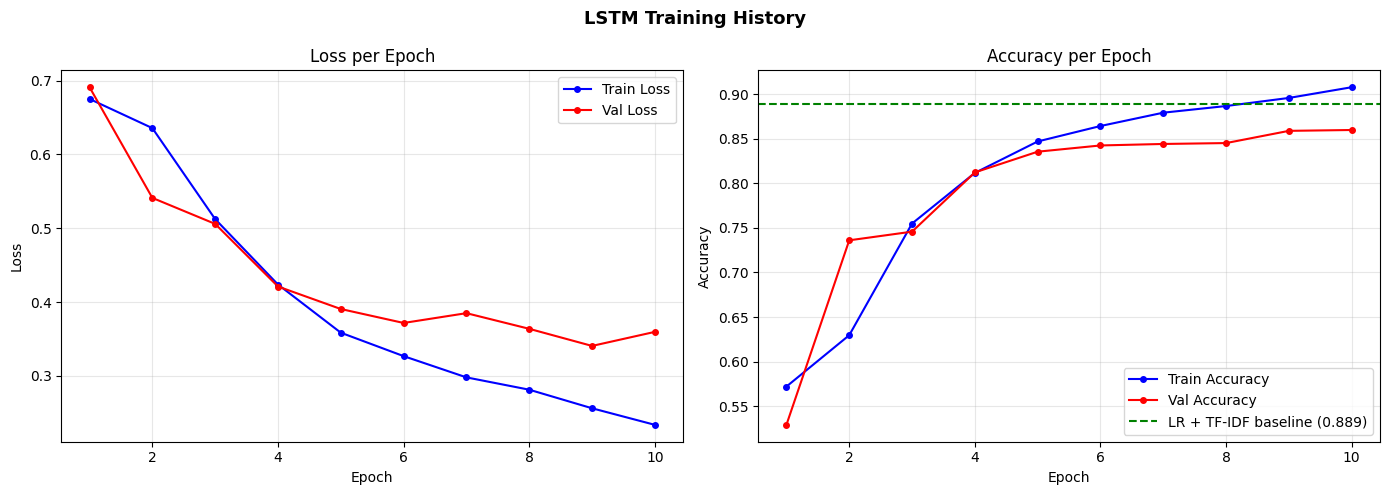

Figure saved.


In [18]:
# ── SECTION D | Cell 17: Continue Training + Learning Curves ────────────────

print("Continuing training for 5 more epochs...")
print(f"{'Epoch':<8}{'Train Loss':<14}{'Train Acc':<14}{'Val Loss':<14}{'Val Acc'}")
print("-" * 58)

for epoch in range(6, 11):
    tr_loss, tr_acc = train_epoch(model, train_loader, optimizer, criterion, device)
    vl_loss, vl_acc = evaluate(model, test_loader, criterion, device)

    train_losses.append(tr_loss)
    val_losses.append(vl_loss)
    train_accs.append(tr_acc)
    val_accs.append(vl_acc)

    print(f"{epoch:<8}{tr_loss:<14.4f}{tr_acc:<14.4f}{vl_loss:<14.4f}{vl_acc:.4f}")

print("\nTraining complete.")
torch.save(model.state_dict(), '../models/lstm_sentiment.pt')
print("Model saved.")

# ── Plot learning curves ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('LSTM Training History', fontsize=13, fontweight='bold')

epochs = range(1, len(train_losses) + 1)

# Loss curves
axes[0].plot(epochs, train_losses, 'b-o', label='Train Loss', markersize=4)
axes[0].plot(epochs, val_losses,   'r-o', label='Val Loss',   markersize=4)
axes[0].set_title('Loss per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Accuracy curves
axes[1].plot(epochs, train_accs, 'b-o', label='Train Accuracy', markersize=4)
axes[1].plot(epochs, val_accs,   'r-o', label='Val Accuracy',   markersize=4)
axes[1].axhline(y=0.889, color='green', linestyle='--',
                label='LR + TF-IDF baseline (0.889)')
axes[1].set_title('Accuracy per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../outputs/figures/lstm_training.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved.")

LSTM CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.84      0.88      0.86     12500
    Positive       0.88      0.84      0.86     12500

    accuracy                           0.86     25000
   macro avg       0.86      0.86      0.86     25000
weighted avg       0.86      0.86      0.86     25000


MODEL COMPARISON — Classical vs Neural
                Model      Type     F1  Accuracy
    Naive Bayes + BoW Classical 0.8431    0.8459
  Linear SVM + TF-IDF Classical 0.8732    0.8738
Logistic Reg + TF-IDF Classical 0.8894    0.8888
 LSTM (Bidirectional)    Neural 0.8566    0.8600


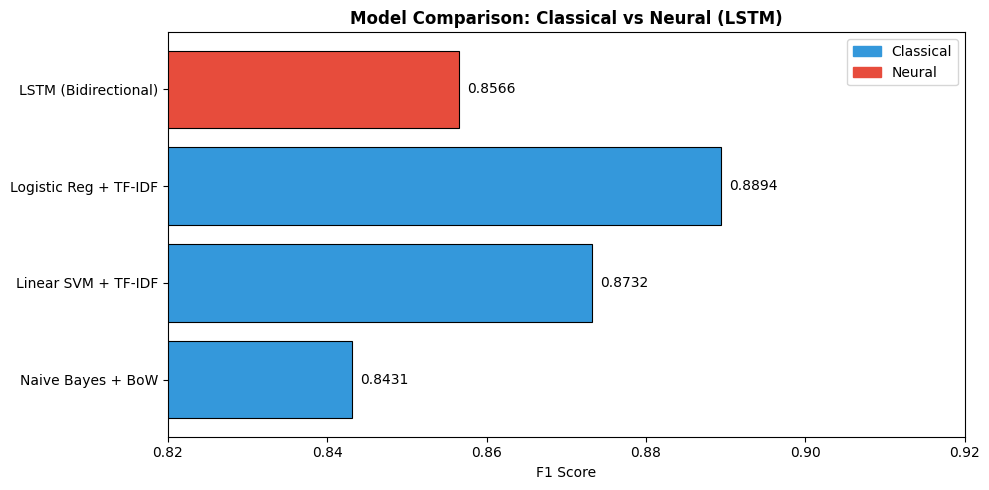

Figure saved.


In [19]:
# ── SECTION D | Cell 18: LSTM Evaluation & Comparison ───────────────────────

from sklearn.metrics import classification_report, f1_score

# ── Get all LSTM predictions ──────────────────────────────────────────────────
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for sequences, labels in test_loader:
        sequences = sequences.to(device)
        outputs   = model(sequences)
        preds     = (torch.sigmoid(outputs) >= 0.5).long().cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.long().numpy())

lstm_f1  = f1_score(all_labels, all_preds)
lstm_acc = sum(p == l for p, l in zip(all_preds, all_labels)) / len(all_labels)

print("LSTM CLASSIFICATION REPORT")
print("=" * 50)
print(classification_report(all_labels, all_preds,
                             target_names=['Negative', 'Positive']))

# ── Full model comparison ─────────────────────────────────────────────────────
comparison = pd.DataFrame([
    {'Model': 'Naive Bayes + BoW',         'Type': 'Classical', 'F1': 0.8431, 'Accuracy': 0.8459},
    {'Model': 'Linear SVM + TF-IDF',       'Type': 'Classical', 'F1': 0.8732, 'Accuracy': 0.8738},
    {'Model': 'Logistic Reg + TF-IDF',     'Type': 'Classical', 'F1': 0.8894, 'Accuracy': 0.8888},
    {'Model': 'LSTM (Bidirectional)',       'Type': 'Neural',    'F1': round(lstm_f1, 4),
                                                                  'Accuracy': round(lstm_acc, 4)},
])

print("\nMODEL COMPARISON — Classical vs Neural")
print("=" * 60)
print(comparison.to_string(index=False))

# ── Visualise comparison ──────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))

colors = ['#3498db' if t == 'Classical' else '#e74c3c'
          for t in comparison['Type']]
bars = ax.barh(comparison['Model'], comparison['F1'],
               color=colors, edgecolor='black', linewidth=0.8)

ax.set_xlim(0.82, 0.92)
ax.set_xlabel('F1 Score')
ax.set_title('Model Comparison: Classical vs Neural (LSTM)', fontweight='bold')

for bar, val in zip(bars, comparison['F1']):
    ax.text(val + 0.001, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=10)

from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color='#3498db', label='Classical'),
    Patch(color='#e74c3c', label='Neural')
])

plt.tight_layout()
plt.savefig('../outputs/figures/model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved.")

In [20]:
# ── SECTION E | Cell 19: LSTM with Attention ────────────────────────────────

class Attention(nn.Module):
    """Additive attention over LSTM hidden states."""
    def __init__(self, hidden_dim):
        super().__init__()
        # hidden_dim*2 because bidirectional
        self.attention = nn.Linear(hidden_dim * 2, 1)

    def forward(self, lstm_output):
        # lstm_output: (batch, seq_len, hidden*2)
        scores  = self.attention(lstm_output)          # (batch, seq_len, 1)
        weights = torch.softmax(scores, dim=1)         # (batch, seq_len, 1)
        context = (weights * lstm_output).sum(dim=1)   # (batch, hidden*2)
        return context, weights.squeeze(2)             # weights: (batch, seq_len)


class LSTMWithAttention(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, n_layers, dropout):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm      = nn.LSTM(embed_dim, hidden_dim,
                                 num_layers=n_layers,
                                 batch_first=True,
                                 dropout=dropout if n_layers > 1 else 0,
                                 bidirectional=True)
        self.attention = Attention(hidden_dim)
        self.dropout   = nn.Dropout(dropout)
        self.fc        = nn.Linear(hidden_dim * 2, 1)

    def forward(self, x):
        embedded          = self.dropout(self.embedding(x))
        lstm_out, _       = self.lstm(embedded)
        context, weights  = self.attention(lstm_out)
        context           = self.dropout(context)
        return self.fc(context).squeeze(1), weights


# ── Train LSTM + Attention ────────────────────────────────────────────────────
attn_model = LSTMWithAttention(
    VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, N_LAYERS, DROPOUT
).to(device)

optimizer_attn = torch.optim.Adam(attn_model.parameters(), lr=LR)

print("Training LSTM + Attention...")
print(f"{'Epoch':<8}{'Train Loss':<14}{'Train Acc':<14}{'Val Loss':<14}{'Val Acc'}")
print("-" * 58)

attn_train_losses, attn_val_losses = [], []
attn_train_accs,   attn_val_accs   = [], []

def train_epoch_attn(model, loader, optimizer, criterion, device):
    model.train()
    total_loss, correct = 0, 0
    for sequences, labels in loader:
        sequences, labels = sequences.to(device), labels.to(device)
        optimizer.zero_grad()
        predictions, _ = model(sequences)
        loss            = criterion(predictions, labels)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item()
        preds       = (torch.sigmoid(predictions) >= 0.5).long()
        correct    += (preds == labels.long()).sum().item()
    return total_loss / len(loader), correct / len(loader.dataset)

def evaluate_attn(model, loader, criterion, device):
    model.eval()
    total_loss, correct = 0, 0
    with torch.no_grad():
        for sequences, labels in loader:
            sequences, labels = sequences.to(device), labels.to(device)
            predictions, _    = model(sequences)
            loss               = criterion(predictions, labels)
            total_loss        += loss.item()
            preds              = (torch.sigmoid(predictions) >= 0.5).long()
            correct           += (preds == labels.long()).sum().item()
    return total_loss / len(loader), correct / len(loader.dataset)

for epoch in range(1, 11):
    tr_loss, tr_acc = train_epoch_attn(attn_model, train_loader,
                                        optimizer_attn, criterion, device)
    vl_loss, vl_acc = evaluate_attn(attn_model, test_loader, criterion, device)

    attn_train_losses.append(tr_loss)
    attn_val_losses.append(vl_loss)
    attn_train_accs.append(tr_acc)
    attn_val_accs.append(vl_acc)

    print(f"{epoch:<8}{tr_loss:<14.4f}{tr_acc:<14.4f}{vl_loss:<14.4f}{vl_acc:.4f}")

torch.save(attn_model.state_dict(), '../models/lstm_attention.pt')
print("\nModel saved.")

Training LSTM + Attention...
Epoch   Train Loss    Train Acc     Val Loss      Val Acc
----------------------------------------------------------
1       0.5032        0.7392        0.3602        0.8424
2       0.3437        0.8502        0.3232        0.8592
3       0.2861        0.8800        0.3124        0.8669
4       0.2499        0.8989        0.3243        0.8673
5       0.2181        0.9120        0.3201        0.8707
6       0.1928        0.9238        0.3068        0.8755
7       0.1726        0.9323        0.3162        0.8767
8       0.1459        0.9441        0.3885        0.8737
9       0.1278        0.9502        0.4202        0.8708
10      0.1107        0.9583        0.3920        0.8718

Model saved.


POSITIVE REVIEW
Prediction : POSITIVE (confidence: 0.675)
Review     : Overall, a well done movie. There were the parts that made me wince, and there were the parts that I threw my hands up a...

Top 20 attended words:
----------------------------------------
  fails                0.0535  ██████████████████████████
  miserably            0.0398  ███████████████████
  fails                0.0238  ███████████
  stand                0.0172  ████████
  movie                0.0152  ███████
  love                 0.0152  ███████
  excess               0.0133  ██████
  subtle               0.0127  ██████
  movie                0.0120  ██████
  india                0.0116  █████
  movie                0.0106  █████
  succeeds             0.0105  █████
  today                0.0102  █████
  real                 0.0097  ████
  pretty               0.0096  ████
  serious              0.0093  ████
  done                 0.0089  ████
  movie                0.0088  ████
  life                 0.008

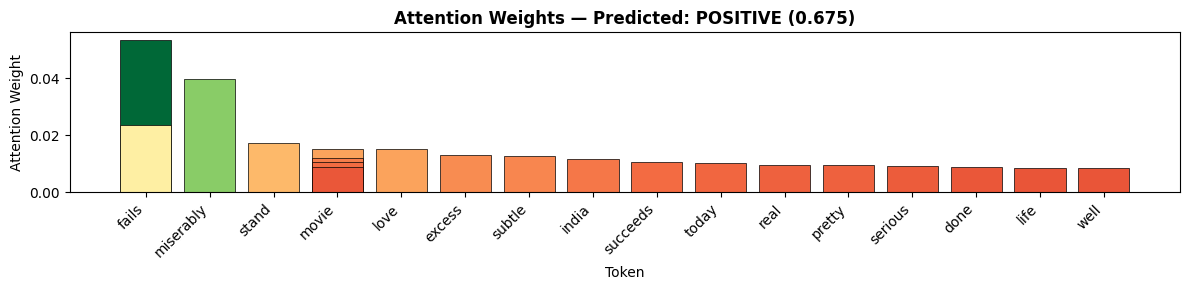


NEGATIVE REVIEW
Prediction : NEGATIVE (confidence: 0.009)
Review     : I had high hopes for this one until they changed the name to 'The Shepherd : Border Patrol, the lamest movie name ever, ...

Top 20 attended words:
----------------------------------------
  bad                  0.0553  ███████████████████████████
  damme                0.0421  █████████████████████
  generic              0.0390  ███████████████████
  damme                0.0295  ██████████████
  fails                0.0286  ██████████████
  van                  0.0252  ████████████
  care                 0.0177  ████████
  damme                0.0166  ████████
  except               0.0164  ████████
  ok                   0.0148  ███████
  van                  0.0146  ███████
  wrong                0.0139  ██████
  name                 0.0120  █████
  fight                0.0115  █████
  average              0.0110  █████
  van                  0.0104  █████
  let                  0.0094  ████
  dialogue          

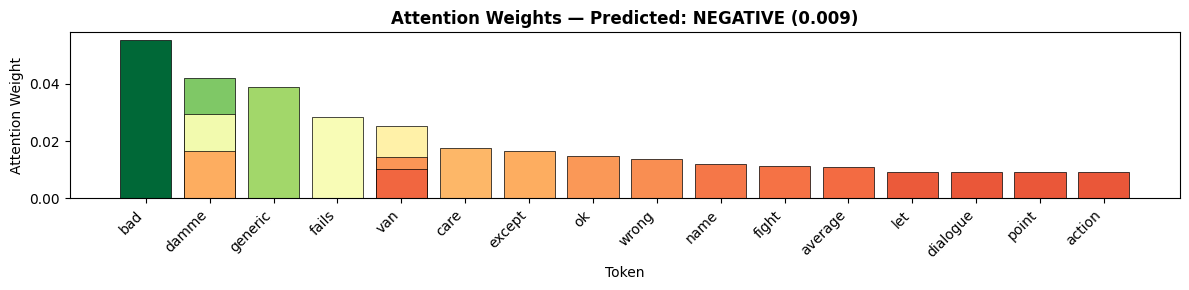


Figures saved.


In [21]:
# ── SECTION E | Cell 20: Attention Visualisation ────────────────────────────

# Reverse vocab for decoding indices back to words
idx_to_word = {idx: word for word, idx in vocab.items()}

def visualize_attention(review_text, model, vocab, idx_to_word,
                        max_len=200, top_n=20):
    """Show which words the model attended to most."""
    model.eval()

    # Preprocess and encode
    clean   = preprocess(review_text)
    tokens  = clean.split()
    encoded = encode(tokens, vocab, max_len)
    tensor  = torch.tensor([encoded], dtype=torch.long).to(device)

    with torch.no_grad():
        logit, weights = attn_model(tensor)
        prob = torch.sigmoid(logit).item()
        pred = 'POSITIVE' if prob >= 0.5 else 'NEGATIVE'

    # Get attention weights for actual tokens (not padding)
    attn_weights = weights[0].cpu().numpy()
    actual_len   = min(len(tokens), max_len)
    tokens_shown = tokens[:actual_len]
    weights_shown = attn_weights[:actual_len]

    # Get top N attended tokens
    top_indices = weights_shown.argsort()[-top_n:][::-1]
    top_tokens  = [(tokens_shown[i], weights_shown[i]) for i in top_indices]

    print(f"Prediction : {pred} (confidence: {prob:.3f})")
    print(f"Review     : {review_text[:120]}...")
    print(f"\nTop {top_n} attended words:")
    print("-" * 40)
    for word, weight in top_tokens:
        bar = '█' * int(weight * 500)
        print(f"  {word:<20} {weight:.4f}  {bar}")

    # ── Heatmap of top 20 tokens ──────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(12, 3))
    top_words   = [t[0] for t in top_tokens]
    top_weights = [t[1] for t in top_tokens]

    bars = ax.bar(top_words, top_weights,
                  color=plt.cm.RdYlGn(
                      [w/max(top_weights) for w in top_weights]
                  ),
                  edgecolor='black', linewidth=0.5)
    ax.set_title(f'Attention Weights — Predicted: {pred} ({prob:.3f})',
                 fontweight='bold')
    ax.set_xlabel('Token')
    ax.set_ylabel('Attention Weight')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    return fig

# ── Test on a positive review ─────────────────────────────────────────────────
print("=" * 60)
print("POSITIVE REVIEW")
print("=" * 60)
positive_review = test_df[test_df['label'] == 1]['text'].iloc[5]
fig1 = visualize_attention(positive_review, attn_model, vocab, idx_to_word)
plt.savefig('../outputs/figures/attention_positive.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Test on a negative review ─────────────────────────────────────────────────
print("\n" + "=" * 60)
print("NEGATIVE REVIEW")
print("=" * 60)
negative_review = test_df[test_df['label'] == 0]['text'].iloc[5]
fig2 = visualize_attention(negative_review, attn_model, vocab, idx_to_word)
plt.savefig('../outputs/figures/attention_negative.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nFigures saved.")

In [22]:
# ── SECTION E | Cell 21: DistilBERT Fine-tuning ─────────────────────────────

from transformers import (DistilBertTokenizerFast,
                          DistilBertForSequenceClassification)
from torch.optim import AdamW
from transformers import get_scheduler

# ── Load tokenizer and model ──────────────────────────────────────────────────
print("Loading DistilBERT...")
tokenizer = DistilBertTokenizerFast.from_pretrained('distilbert-base-uncased')
bert_model = DistilBertForSequenceClassification.from_pretrained(
    'distilbert-base-uncased',
    num_labels=2
).to(device)

total_params = sum(p.numel() for p in bert_model.parameters() if p.requires_grad)
print(f"DistilBERT trainable parameters: {total_params:,}")

# ── Tokenize dataset ──────────────────────────────────────────────────────────
# Use RAW text — BERT has its own tokenizer, do NOT use our preprocessed text
BERT_MAX_LEN = 256
BERT_BATCH   = 16   # Smaller batch — BERT is memory intensive

print("Tokenizing training set...")
train_encodings = tokenizer(
    train_df['text'].tolist(),
    truncation=True,
    padding=True,
    max_length=BERT_MAX_LEN,
    return_tensors='pt'
)

print("Tokenizing test set...")
test_encodings = tokenizer(
    test_df['text'].tolist(),
    truncation=True,
    padding=True,
    max_length=BERT_MAX_LEN,
    return_tensors='pt'
)

print("Tokenization complete.")

# ── Dataset ───────────────────────────────────────────────────────────────────
class BERTDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels    = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            'input_ids':      self.encodings['input_ids'][idx],
            'attention_mask': self.encodings['attention_mask'][idx],
            'labels':         self.labels[idx]
        }

bert_train = BERTDataset(train_encodings, y_train.tolist())
bert_test  = BERTDataset(test_encodings,  y_test.tolist())

bert_train_loader = DataLoader(bert_train, batch_size=BERT_BATCH, shuffle=True)
bert_test_loader  = DataLoader(bert_test,  batch_size=BERT_BATCH, shuffle=False)

print(f"Train batches: {len(bert_train_loader)}")
print(f"Test batches : {len(bert_test_loader)}")

# ── Optimizer and scheduler ───────────────────────────────────────────────────
N_BERT_EPOCHS = 3
optimizer_bert = AdamW(bert_model.parameters(), lr=2e-5, weight_decay=0.01)
total_steps    = len(bert_train_loader) * N_BERT_EPOCHS

scheduler = get_scheduler(
    'linear',
    optimizer=optimizer_bert,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps
)

# ── Training loop ─────────────────────────────────────────────────────────────
def train_bert_epoch(model, loader, optimizer, scheduler, device):
    model.train()
    total_loss, correct = 0, 0
    for batch in loader:
        input_ids      = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels         = batch['labels'].to(device)

        optimizer.zero_grad()
        outputs = model(input_ids=input_ids,
                        attention_mask=attention_mask,
                        labels=labels)
        loss    = outputs.loss
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()

        total_loss += loss.item()
        preds       = outputs.logits.argmax(dim=1)
        correct    += (preds == labels).sum().item()
    return total_loss / len(loader), correct / len(loader.dataset)

def evaluate_bert(model, loader, device):
    model.eval()
    total_loss, correct = 0, 0
    with torch.no_grad():
        for batch in loader:
            input_ids      = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels         = batch['labels'].to(device)
            outputs = model(input_ids=input_ids,
                            attention_mask=attention_mask,
                            labels=labels)
            total_loss += outputs.loss.item()
            preds       = outputs.logits.argmax(dim=1)
            correct    += (preds == labels).sum().item()
    return total_loss / len(loader), correct / len(loader.dataset)

# ── Run training ──────────────────────────────────────────────────────────────
print("\nFine-tuning DistilBERT...")
print(f"{'Epoch':<8}{'Train Loss':<14}{'Train Acc':<14}{'Val Loss':<14}{'Val Acc'}")
print("-" * 58)

bert_train_losses, bert_val_losses = [], []
bert_train_accs,   bert_val_accs   = [], []

for epoch in range(1, N_BERT_EPOCHS + 1):
    tr_loss, tr_acc = train_bert_epoch(bert_model, bert_train_loader,
                                        optimizer_bert, scheduler, device)
    vl_loss, vl_acc = evaluate_bert(bert_model, bert_test_loader, device)

    bert_train_losses.append(tr_loss)
    bert_val_losses.append(vl_loss)
    bert_train_accs.append(tr_acc)
    bert_val_accs.append(vl_acc)

    print(f"{epoch:<8}{tr_loss:<14.4f}{tr_acc:<14.4f}{vl_loss:<14.4f}{vl_acc:.4f}")
    torch.save(bert_model.state_dict(), f'../models/distilbert_epoch{epoch}.pt')

print("\nFine-tuning complete.")

Loading DistilBERT...


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT trainable parameters: 66,955,010
Tokenizing training set...
Tokenizing test set...
Tokenization complete.
Train batches: 1563
Test batches : 1563

Fine-tuning DistilBERT...
Epoch   Train Loss    Train Acc     Val Loss      Val Acc
----------------------------------------------------------
1       0.3326        0.8524        0.2376        0.9084
2       0.1814        0.9360        0.2783        0.9128
3       0.1046        0.9711        0.3417        0.9133

Fine-tuning complete.


Evaluating DistilBERT on test set...

DistilBERT CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.92      0.91      0.91     12500
    Positive       0.91      0.92      0.91     12500

    accuracy                           0.91     25000
   macro avg       0.91      0.91      0.91     25000
weighted avg       0.91      0.91      0.91     25000


FINAL MODEL COMPARISON
                  Model        Type     F1  Accuracy
      Naive Bayes + BoW   Classical 0.8431    0.8459
    Linear SVM + TF-IDF   Classical 0.8732    0.8738
  Logistic Reg + TF-IDF   Classical 0.8894    0.8888
   LSTM (Bidirectional)      Neural 0.8566    0.8600
       LSTM + Attention      Neural 0.8767    0.8767
DistilBERT (fine-tuned) Transformer 0.9139    0.9133


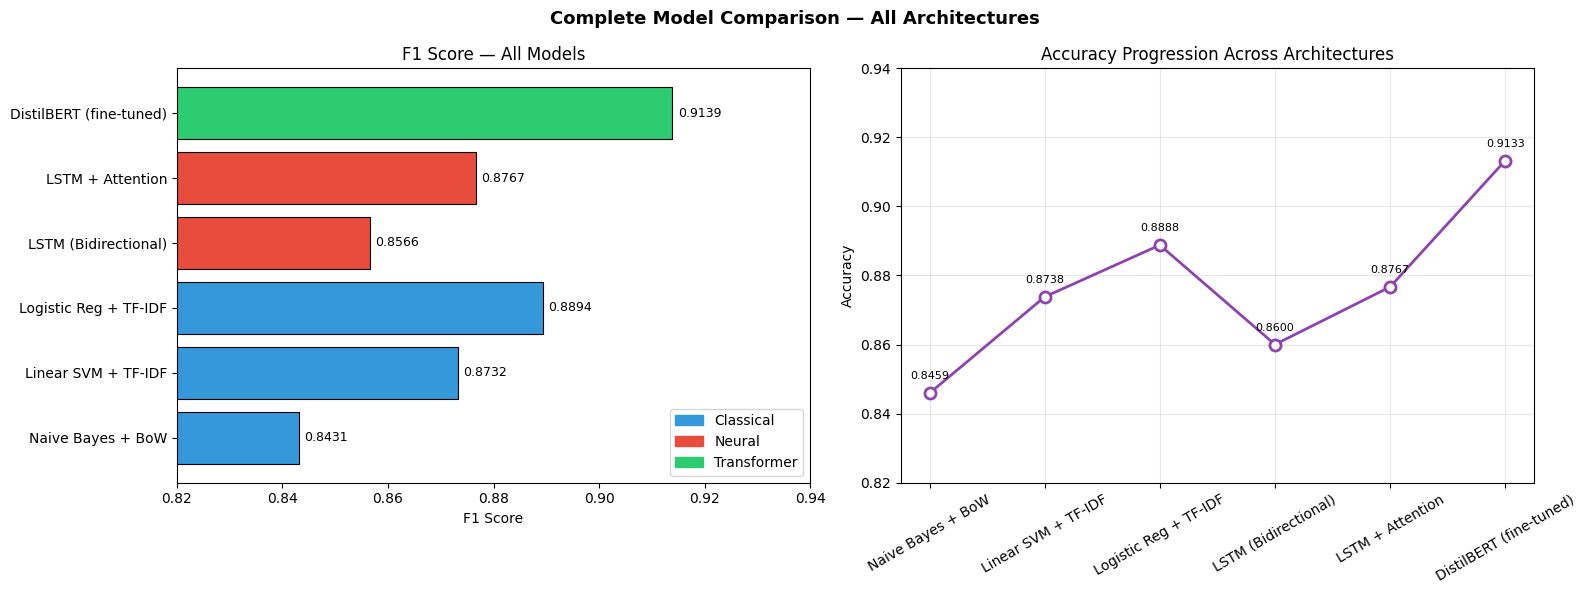

Figure saved.


In [23]:
# ── SECTION E | Cell 22: Final Comparison ───────────────────────────────────

from sklearn.metrics import classification_report, f1_score, accuracy_score

# ── Get BERT predictions ──────────────────────────────────────────────────────
print("Evaluating DistilBERT on test set...")
bert_model.eval()
bert_preds, bert_labels = [], []

with torch.no_grad():
    for batch in bert_test_loader:
        input_ids      = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels         = batch['labels'].to(device)
        outputs        = bert_model(input_ids=input_ids,
                                    attention_mask=attention_mask)
        preds          = outputs.logits.argmax(dim=1)
        bert_preds.extend(preds.cpu().numpy())
        bert_labels.extend(labels.cpu().numpy())

bert_f1  = f1_score(bert_labels, bert_preds)
bert_acc = accuracy_score(bert_labels, bert_preds)

print("\nDistilBERT CLASSIFICATION REPORT")
print("=" * 50)
print(classification_report(bert_labels, bert_preds,
                             target_names=['Negative', 'Positive']))

# ── Full comparison table ─────────────────────────────────────────────────────
final_comparison = pd.DataFrame([
    {'Model': 'Naive Bayes + BoW',      'Type': 'Classical',  'F1': 0.8431, 'Accuracy': 0.8459},
    {'Model': 'Linear SVM + TF-IDF',    'Type': 'Classical',  'F1': 0.8732, 'Accuracy': 0.8738},
    {'Model': 'Logistic Reg + TF-IDF',  'Type': 'Classical',  'F1': 0.8894, 'Accuracy': 0.8888},
    {'Model': 'LSTM (Bidirectional)',    'Type': 'Neural',     'F1': 0.8566, 'Accuracy': 0.8600},
    {'Model': 'LSTM + Attention',        'Type': 'Neural',     'F1': 0.8767, 'Accuracy': 0.8767},
    {'Model': 'DistilBERT (fine-tuned)', 'Type': 'Transformer','F1': round(bert_f1, 4),
                                                                'Accuracy': round(bert_acc, 4)},
])

print("\nFINAL MODEL COMPARISON")
print("=" * 65)
print(final_comparison.to_string(index=False))

# ── Visualisation ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Complete Model Comparison — All Architectures',
             fontsize=13, fontweight='bold')

# Plot 1: F1 bar chart
type_colors = {
    'Classical':   '#3498db',
    'Neural':      '#e74c3c',
    'Transformer': '#2ecc71'
}
colors = [type_colors[t] for t in final_comparison['Type']]

bars = axes[0].barh(final_comparison['Model'],
                    final_comparison['F1'],
                    color=colors, edgecolor='black', linewidth=0.8)
axes[0].set_xlim(0.82, 0.94)
axes[0].set_xlabel('F1 Score')
axes[0].set_title('F1 Score — All Models')
for bar, val in zip(bars, final_comparison['F1']):
    axes[0].text(val + 0.001, bar.get_y() + bar.get_height()/2,
                 f'{val:.4f}', va='center', fontsize=9)

from matplotlib.patches import Patch
axes[0].legend(handles=[
    Patch(color='#3498db', label='Classical'),
    Patch(color='#e74c3c', label='Neural'),
    Patch(color='#2ecc71', label='Transformer')
])

# Plot 2: Accuracy progression — the narrative arc
axes[1].plot(final_comparison['Model'],
             final_comparison['Accuracy'],
             'o-', color='#8e44ad', linewidth=2,
             markersize=8, markerfacecolor='white',
             markeredgewidth=2)

axes[1].set_ylabel('Accuracy')
axes[1].set_title('Accuracy Progression Across Architectures')
axes[1].set_ylim(0.82, 0.94)
axes[1].tick_params(axis='x', rotation=30)
axes[1].grid(alpha=0.3)

for i, row in final_comparison.iterrows():
    axes[1].annotate(f"{row['Accuracy']:.4f}",
                     (row['Model'], row['Accuracy']),
                     textcoords="offset points",
                     xytext=(0, 10), ha='center', fontsize=8)

plt.tight_layout()
plt.savefig('../outputs/figures/final_comparison.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved.")

ROC-AUC SCORES
Logistic Regression + TF-IDF : 0.9569
LSTM + Attention             : 0.9428
DistilBERT (fine-tuned)      : 0.9714


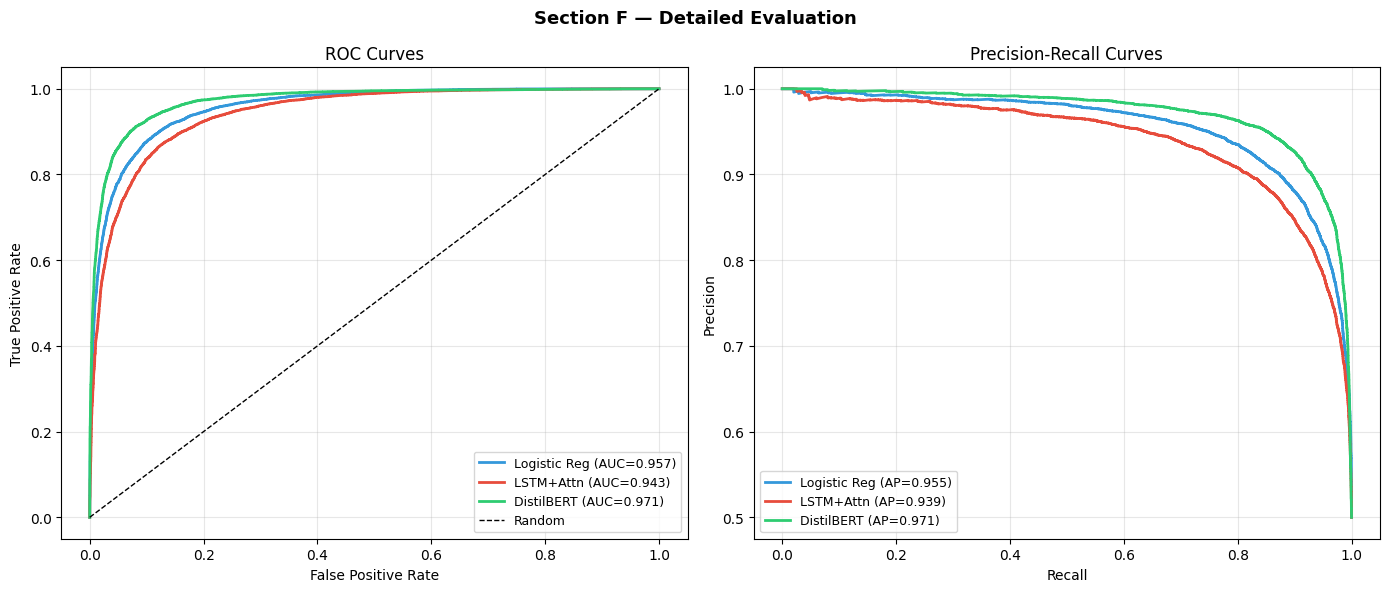

Figure saved.


In [24]:
# ── SECTION F | Cell 23: Detailed Evaluation ────────────────────────────────

from sklearn.metrics import (roc_auc_score, roc_curve,
                              precision_recall_curve, average_precision_score)

# ── Get probability scores for ROC curves ────────────────────────────────────

# Logistic Regression probabilities
lr_probs    = best_model.predict_proba(X_test_tfidf)[:, 1]

# LSTM + Attention probabilities
attn_model.eval()
attn_probs = []
with torch.no_grad():
    for sequences, labels in test_loader:
        sequences = sequences.to(device)
        logits, _ = attn_model(sequences)
        probs     = torch.sigmoid(logits).cpu().numpy()
        attn_probs.extend(probs)
attn_probs = np.array(attn_probs)

# DistilBERT probabilities
bert_model.eval()
bert_probs = []
with torch.no_grad():
    for batch in bert_test_loader:
        input_ids      = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        outputs        = bert_model(input_ids=input_ids,
                                    attention_mask=attention_mask)
        probs = torch.softmax(outputs.logits, dim=1)[:, 1].cpu().numpy()
        bert_probs.extend(probs)
bert_probs = np.array(bert_probs)

# ── ROC AUC scores ────────────────────────────────────────────────────────────
lr_auc   = roc_auc_score(y_test, lr_probs)
attn_auc = roc_auc_score(y_test, attn_probs)
bert_auc = roc_auc_score(y_test, bert_probs)

print("ROC-AUC SCORES")
print("=" * 40)
print(f"Logistic Regression + TF-IDF : {lr_auc:.4f}")
print(f"LSTM + Attention             : {attn_auc:.4f}")
print(f"DistilBERT (fine-tuned)      : {bert_auc:.4f}")

# ── Plot ROC curves ───────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Section F — Detailed Evaluation', fontsize=13, fontweight='bold')

# ROC Curves
for probs, label, color, auc in [
    (lr_probs,   f'Logistic Reg (AUC={lr_auc:.3f})',   '#3498db', lr_auc),
    (attn_probs, f'LSTM+Attn (AUC={attn_auc:.3f})',    '#e74c3c', attn_auc),
    (bert_probs, f'DistilBERT (AUC={bert_auc:.3f})',   '#2ecc71', bert_auc),
]:
    fpr, tpr, _ = roc_curve(y_test, probs)
    axes[0].plot(fpr, tpr, color=color, linewidth=2, label=label)

axes[0].plot([0,1], [0,1], 'k--', linewidth=1, label='Random')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curves')
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3)

# Precision-Recall Curves
for probs, label, color in [
    (lr_probs,   'Logistic Reg', '#3498db'),
    (attn_probs, 'LSTM+Attn',    '#e74c3c'),
    (bert_probs, 'DistilBERT',   '#2ecc71'),
]:
    prec, rec, _ = precision_recall_curve(y_test, probs)
    ap = average_precision_score(y_test, probs)
    axes[1].plot(rec, prec, color=color, linewidth=2,
                 label=f'{label} (AP={ap:.3f})')

axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curves')
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../outputs/figures/roc_pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved.")

In [25]:
# ── SECTION F | Cell 24: DistilBERT Error Analysis ──────────────────────────

# Build error dataframe for DistilBERT
bert_error_df = test_df.copy()
bert_error_df['bert_pred']    = bert_preds
bert_error_df['bert_prob']    = bert_probs
bert_error_df['bert_correct'] = bert_error_df['bert_pred'] == bert_error_df['label']

bert_errors   = bert_error_df[bert_error_df['bert_correct'] == False].copy()
bert_correct  = bert_error_df[bert_error_df['bert_correct'] == True].copy()

bert_fp = bert_errors[bert_errors['label'] == 0]  # predicted positive, actually negative
bert_fn = bert_errors[bert_errors['label'] == 1]  # predicted negative, actually positive

print(f"DistilBERT Errors     : {len(bert_errors):,} / {len(bert_error_df):,} ({len(bert_errors)/len(bert_error_df)*100:.1f}%)")
print(f"False Positives       : {len(bert_fp):,}")
print(f"False Negatives       : {len(bert_fn):,}")

# ── High confidence errors — most interesting cases ───────────────────────────
print("\n" + "=" * 60)
print("HIGH CONFIDENCE ERRORS (model was very wrong)")
print("=" * 60)

# False positives where model was very confident
confident_fp = bert_fp.copy()
confident_fp['confidence'] = bert_fp['bert_prob']
confident_fp = confident_fp.nlargest(3, 'confidence')

print("\nMost confident FALSE POSITIVES:")
for _, row in confident_fp.iterrows():
    print(f"\n  Confidence : {row['confidence']:.3f} (predicted positive)")
    print(f"  Review     : {row['text'][:200]}")
    print("-" * 50)

# False negatives where model was very confident
confident_fn = bert_fn.copy()
confident_fn['confidence'] = 1 - bert_fn['bert_prob']
confident_fn = confident_fn.nlargest(3, 'confidence')

print("\nMost confident FALSE NEGATIVES:")
for _, row in confident_fn.iterrows():
    print(f"\n  Confidence : {row['confidence']:.3f} (predicted negative)")
    print(f"  Review     : {row['text'][:200]}")
    print("-" * 50)

# ── Compare error rates: LR vs DistilBERT ─────────────────────────────────────
lr_errors   = (~test_df['correct']).sum()
bert_errors_n = len(bert_errors)

print("\n" + "=" * 60)
print("ERROR REDUCTION: Logistic Regression → DistilBERT")
print("=" * 60)
print(f"LR errors       : {lr_errors:,}  ({lr_errors/len(test_df)*100:.1f}%)")
print(f"DistilBERT errors: {bert_errors_n:,} ({bert_errors_n/len(test_df)*100:.1f}%)")
print(f"Errors reduced  : {lr_errors - bert_errors_n:,} fewer mistakes")

DistilBERT Errors     : 2,168 / 25,000 (8.7%)
False Positives       : 1,177
False Negatives       : 991

HIGH CONFIDENCE ERRORS (model was very wrong)

Most confident FALSE POSITIVES:

  Confidence : 0.998 (predicted positive)
  Review     : All in all, don't expect much and you won't be disappointed.<br /><br />And if you want to see a movie that will take you back to 1983, this will do that for sure. The only reason I gave this movie 2 
--------------------------------------------------

  Confidence : 0.998 (predicted positive)
  Review     : Why wasn't this voted for Best Picture of 1998? This has to be the best movie ever. It makes something like Citzen Kane look like utter crap, come on, Citzen Kane wasn't even in color! I love this mov
--------------------------------------------------

  Confidence : 0.998 (predicted positive)
  Review     : I saw Winnie's Heffalump a couple of days ago. A nice story based on well known characters created by A.A.Milne. Although Winnie, Piglet, 

IMPROVEMENT: CONFIDENCE-BASED THRESHOLDING
Default threshold (0.50):
  Precision : 0.9072
  Recall    : 0.9207
  F1        : 0.9139
  Coverage  : 100.0% (all samples predicted)

Threshold sweep results:
 Threshold  Precision  Recall     F1  Coverage
      0.50     0.9072  0.9207 0.9139    1.0000
      0.55     0.9091  0.9221 0.9155    0.9962
      0.60     0.9110  0.9240 0.9175    0.9922
      0.65     0.9133  0.9259 0.9195    0.9881
      0.70     0.9148  0.9278 0.9213    0.9845
      0.75     0.9182  0.9295 0.9238    0.9791
      0.80     0.9200  0.9313 0.9257    0.9733
      0.85     0.9226  0.9337 0.9281    0.9662
      0.90     0.9271  0.9375 0.9323    0.9553
      0.95     0.9336  0.9439 0.9387    0.9356

Best threshold : 0.95
  F1           : 0.9387  (vs 0.9139 baseline)
  Precision    : 0.9336
  Coverage     : 93.6% of samples


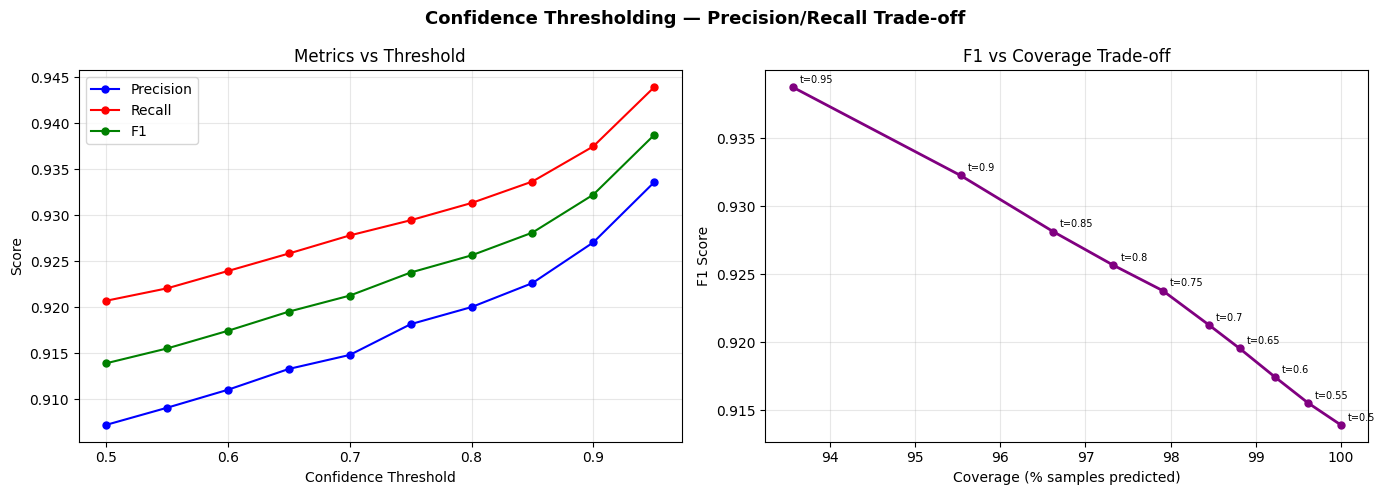


Figure saved.


In [26]:
# ── SECTION F | Cell 25: Improvement — Confidence Thresholding ──────────────

from sklearn.metrics import precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import numpy as np

# ── Baseline at default threshold 0.5 ────────────────────────────────────────
default_preds = (bert_probs >= 0.5).astype(int)
default_f1    = f1_score(y_test, default_preds)
default_prec  = precision_score(y_test, default_preds)
default_rec   = recall_score(y_test, default_preds)

print("IMPROVEMENT: CONFIDENCE-BASED THRESHOLDING")
print("=" * 60)
print(f"Default threshold (0.50):")
print(f"  Precision : {default_prec:.4f}")
print(f"  Recall    : {default_rec:.4f}")
print(f"  F1        : {default_f1:.4f}")
print(f"  Coverage  : 100.0% (all samples predicted)")

# ── Sweep thresholds ──────────────────────────────────────────────────────────
thresholds   = np.arange(0.50, 0.96, 0.05)
results_thr  = []

for thr in thresholds:
    # High confidence predictions only
    high_conf_mask = (bert_probs >= thr) | (bert_probs <= (1 - thr))
    if high_conf_mask.sum() == 0:
        continue

    preds_thr  = (bert_probs[high_conf_mask] >= 0.5).astype(int)
    labels_thr = y_test[high_conf_mask]
    coverage   = high_conf_mask.mean()

    results_thr.append({
        'Threshold': round(thr, 2),
        'Precision': precision_score(labels_thr, preds_thr),
        'Recall':    recall_score(labels_thr, preds_thr),
        'F1':        f1_score(labels_thr, preds_thr),
        'Coverage':  coverage
    })

thr_df = pd.DataFrame(results_thr)
print(f"\nThreshold sweep results:")
print(thr_df.round(4).to_string(index=False))

# ── Find optimal threshold ────────────────────────────────────────────────────
best_thr = thr_df.loc[thr_df['F1'].idxmax()]
print(f"\nBest threshold : {best_thr['Threshold']}")
print(f"  F1           : {best_thr['F1']:.4f}  (vs {default_f1:.4f} baseline)")
print(f"  Precision    : {best_thr['Precision']:.4f}")
print(f"  Coverage     : {best_thr['Coverage']*100:.1f}% of samples")

# ── Visualise ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Confidence Thresholding — Precision/Recall Trade-off',
             fontsize=13, fontweight='bold')

axes[0].plot(thr_df['Threshold'], thr_df['Precision'],
             'b-o', label='Precision', markersize=5)
axes[0].plot(thr_df['Threshold'], thr_df['Recall'],
             'r-o', label='Recall', markersize=5)
axes[0].plot(thr_df['Threshold'], thr_df['F1'],
             'g-o', label='F1', markersize=5)
axes[0].set_xlabel('Confidence Threshold')
axes[0].set_ylabel('Score')
axes[0].set_title('Metrics vs Threshold')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(thr_df['Coverage'] * 100, thr_df['F1'],
             'purple', marker='o', linewidth=2, markersize=5)
axes[1].set_xlabel('Coverage (% samples predicted)')
axes[1].set_ylabel('F1 Score')
axes[1].set_title('F1 vs Coverage Trade-off')
axes[1].grid(alpha=0.3)
for _, row in thr_df.iterrows():
    axes[1].annotate(f"t={row['Threshold']}",
                     (row['Coverage']*100, row['F1']),
                     textcoords="offset points",
                     xytext=(5, 3), fontsize=7)

plt.tight_layout()
plt.savefig('../outputs/figures/threshold_optimization.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("\nFigure saved.")